# Exploratory Data Analysis: Merged Customer Dataset

**Author:** Diane Ingabire · Formative 2: Multimodal Data Preprocessing

This notebook explores `merged_dataset.csv`, which is the result of joining `customer_transactions.csv` and `customer_social_profiles.csv` (see `armstrong_product_model/`). The aim is to understand the data **before** modelling:

1. Structure and variable types
2. Summary statistics
3. Data quality: missing values, duplicates, redundant columns
4. Distributions of the numeric variables
5. Outliers
6. Correlations between numeric variables
7. Relationship of each feature with the target `product_category`
8. Implications for the product recommendation model

Every figure is saved to `notebooks/plots/` so it can be reused in the report.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "armstrong_product_model" / "merged_dataset.csv"
PLOTS = ROOT / "notebooks" / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Plot style: light surface, recessive grid, one fixed colour per product category
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE = "#2a78d6"
CATEGORY_COLORS = {"Books": "#2a78d6", "Clothing": "#eb6834", "Electronics": "#1baf7a",
                   "Groceries": "#eda100", "Sports": "#e87ba4"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#b42f2f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10, "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(PLOTS / f"{name}.png", dpi=130, bbox_inches="tight")

## 1. Load the data

The column names produced by the merge script carry aggregation suffixes (`_mean`, `_most_common_value`). They are renamed to short, readable names for this analysis only; the source file is not modified.

In [2]:
raw = pd.read_csv(DATA)

RENAME = {
    "social_media_platform_most_common_value": "main_platform",
    "review_sentiment_most_common_value": "review_sentiment",
    "engagement_score_mean": "engagement_score",
    "purchase_interest_score_mean": "purchase_interest_score",
    "social_media_platform_nunique": "platform_nunique",
    "social_media_platform": "main_platform",
}
df = raw.rename(columns={k: v for k, v in RENAME.items() if k in raw.columns})
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

print(f"Rows: {len(df)}   Columns: {df.shape[1]}")
print(f"Customers: {df['customer_id'].nunique()}   "
      f"Period: {df['purchase_date'].min():%d %b %Y} to {df['purchase_date'].max():%d %b %Y}")
df.head()

Rows: 150   Columns: 17
Customers: 75   Period: 01 Jan 2024 to 29 May 2024


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,prior_purchase_count,prior_avg_purchase_amount,prior_avg_customer_rating,platform_nunique,main_platform,engagement_score,purchase_interest_score,review_sentiment,social_platform_count,engagement_level
0,100,1113,172,2024-04-22,Clothing,4.0,100,0,NaN,NaN,2.0,Instagram,77.0,4.4,Negative,2.0,High
1,100,1147,387,2024-05-26,Books,4.6,100,1,172.0,4.00,2.0,Instagram,77.0,4.4,Negative,2.0,High
2,101,1017,271,2024-01-17,Books,2.1,101,0,NaN,NaN,1.0,Twitter,68.0,1.0,Neutral,1.0,Medium
3,101,1021,192,2024-01-21,Groceries,3.4,101,1,271.0,2.10,1.0,Twitter,68.0,1.0,Neutral,1.0,Medium
4,101,1059,408,2024-02-28,Books,2.5,101,2,231.5,2.75,1.0,Twitter,68.0,1.0,Neutral,1.0,Medium


## 2. Variable types

In [3]:
def kind(col):
    if col in {"customer_id", "customer_id_legacy", "transaction_id"}:
        return "identifier"
    if col == "product_category":
        return "target (categorical)"
    if pd.api.types.is_datetime64_any_dtype(df[col]):
        return "datetime"
    if pd.api.types.is_numeric_dtype(df[col]):
        return "numeric (discrete)" if df[col].dropna().mod(1).eq(0).all() else "numeric (continuous)"
    return "categorical"


variables = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "variable_type": [kind(c) for c in df.columns],
    "unique_values": df.nunique(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
})
variables

,dtype,variable_type,unique_values,missing,missing_%
customer_id_legacy,int64,identifier,75,0,0.0
transaction_id,int64,identifier,150,0,0.0
purchase_amount,int64,numeric (discrete),120,0,0.0
purchase_date,datetime64[us],datetime,150,0,0.0
product_category,str,target (categorical),5,0,0.0
customer_rating,float64,numeric (continuous),37,0,0.0
customer_id,int64,identifier,75,0,0.0
prior_purchase_count,int64,numeric (discrete),6,0,0.0
prior_avg_purchase_amount,float64,numeric (continuous),71,75,50.0
prior_avg_customer_rating,float64,numeric (continuous),47,75,50.0


**Interpretation**

- The dataset has **one row per transaction** (150 rows, 75 customers). It contains identifiers, one datetime column, numeric behaviour and engagement features, three categorical features, and the categorical target `product_category`.
- `customer_id_legacy` and `customer_id` hold the same values (the join key after the `A` prefix was removed). Identifiers carry no predictive meaning and must not be used as model features.

## 3. Summary statistics

In [4]:
NUMERIC = ["purchase_amount", "customer_rating", "prior_purchase_count", "prior_avg_purchase_amount",
           "prior_avg_customer_rating", "engagement_score", "purchase_interest_score", "social_platform_count"]
CATEGORICAL = ["product_category", "main_platform", "review_sentiment", "engagement_level"]

summary = df[NUMERIC].describe().T
summary["skew"] = df[NUMERIC].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.00,388.5,495.0,0.06
customer_rating,150.0,2.99,1.17,1.0,2.10,3.00,4.0,5.0,-0.08
prior_purchase_count,150.0,0.81,1.03,0.0,0.00,0.50,1.0,5.0,1.47
prior_avg_purchase_amount,75.0,271.60,99.66,62.0,214.50,267.00,333.0,490.0,0.03
prior_avg_customer_rating,75.0,2.87,0.90,1.1,2.28,2.80,3.6,4.8,-0.09
engagement_score,117.0,74.15,12.67,50.0,66.50,77.00,83.0,99.0,-0.33
purchase_interest_score,117.0,3.08,1.04,1.0,2.67,3.13,3.7,4.8,-0.32
social_platform_count,117.0,1.60,0.73,1.0,1.00,1.00,2.0,4.0,1.20


In [5]:
df[CATEGORICAL].astype("object").describe().T

,count,unique,top,freq
product_category,150,5,Sports,35
main_platform,117,5,Facebook,32
review_sentiment,117,3,Positive,44
engagement_level,117,2,High,78


In [6]:
per_customer = df.groupby("customer_id").size()
print("Transactions per customer:", per_customer.describe().round(2).to_dict())

Transactions per customer: {'count': 75.0, 'mean': 2.0, 'std': 1.12, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 2.5, 'max': 6.0}


**Interpretation**

- **Purchase amount** ranges from 51 to 495 (mean ≈ 281, median 274). The mean and median are almost equal and the skew is ≈ 0, so the distribution is symmetric.
- **Customer rating** spans the full 1–5 scale with a mean of ≈ 3.0.
- **Engagement score** (50–99, mean ≈ 74) and **purchase interest** (1–4.8, mean ≈ 3.1) are slightly left-skewed.
- Customers have **1 to 6 transactions** (median 2). Purchase histories are short, which limits how much the `prior_*` features can learn.
- **Sports** (35) and **Electronics** (34) are the most frequent categories. **Facebook** is the most common main platform, and **Positive** is the most common review sentiment.

## 4. Data quality: missing values, duplicates and redundant columns

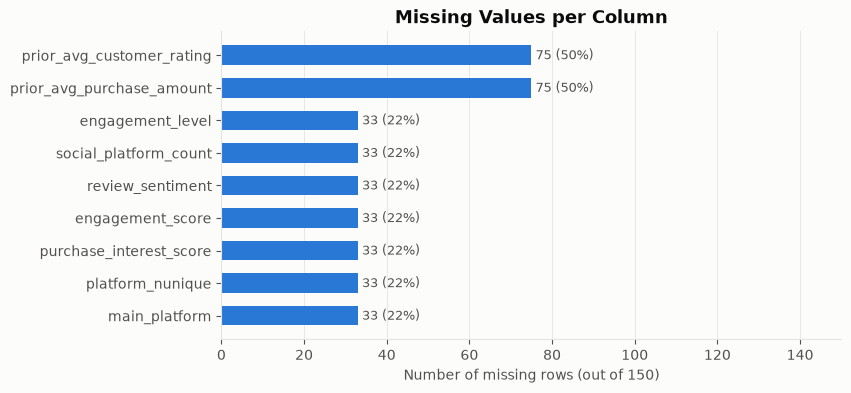

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v + 1, y, f"{v} ({v / len(df):.0%})", va="center", color=INK_2, fontsize=9)
ax.set_title("Missing Values per Column")
ax.set_xlabel("Number of missing rows (out of 150)")
ax.set_xlim(0, len(df))
ax.grid(axis="y", visible=False)
save(fig, "01_missing_values")
plt.show()

In [8]:
first_purchase = df["prior_purchase_count"].eq(0)
no_profile = df["engagement_score"].isna()

print("Exact duplicate rows:          ", df.duplicated().sum())
print("Duplicate transaction IDs:     ", df["transaction_id"].duplicated().sum())
print("Rows that are a first purchase:", first_purchase.sum(),
      "| prior_avg_* missing on exactly those rows:",
      df.loc[first_purchase, "prior_avg_purchase_amount"].isna().all())
print("Rows without a social profile: ", no_profile.sum(),
      f"from {df.loc[no_profile, 'customer_id'].nunique()} customers")
if "platform_nunique" in df:
    print("platform_nunique == social_platform_count:",
          df["platform_nunique"].equals(df["social_platform_count"]))
print("customer_id == customer_id_legacy:", df["customer_id"].equals(df["customer_id_legacy"]))

Exact duplicate rows:           0
Duplicate transaction IDs:      0
Rows that are a first purchase: 75 | prior_avg_* missing on exactly those rows: True
Rows without a social profile:  33 from 14 customers
platform_nunique == social_platform_count: True
customer_id == customer_id_legacy: True


**Interpretation**

The missing values are **structural**. They come from how the data was built, not from data-entry errors:

- **`prior_avg_purchase_amount` / `prior_avg_customer_rating` (75 rows, 50%).** These are missing exactly on each customer's **first purchase**, because there is no earlier history to average. Filling them with the median is reasonable. A cleaner alternative is to add a `has_history` flag so the model can tell "no history" apart from "average history".
- **Social features (33 rows, 22%).** These come from 14 customers who appear in the transactions but have **no social profile**. The left join keeps their transactions, which is correct because each transaction carries the target label. Their social fields are therefore empty. Imputation, or an explicit "Unknown" category, is needed before modelling.
- **No duplicate rows and no duplicate transaction IDs**, so the merge did not multiply transactions. Aggregating the social profiles to one row per customer before joining worked as intended.
- **Redundant columns:** `platform_nunique` is identical to `social_platform_count`, and `customer_id` is identical to `customer_id_legacy`. One of each pair should be dropped.

## 5. Distributions of numeric variables

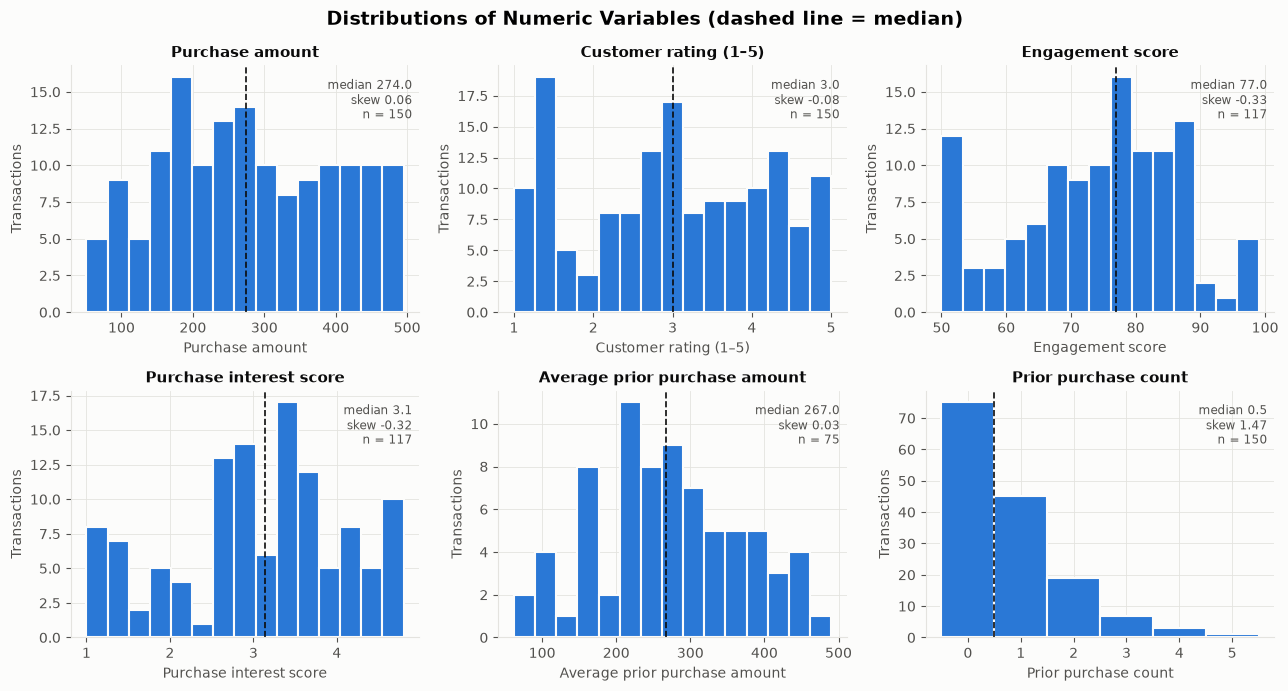

In [9]:
DIST = [("purchase_amount", "Purchase amount"), ("customer_rating", "Customer rating (1–5)"),
        ("engagement_score", "Engagement score"), ("purchase_interest_score", "Purchase interest score"),
        ("prior_avg_purchase_amount", "Average prior purchase amount"), ("prior_purchase_count", "Prior purchase count")]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, label) in zip(axes.ravel(), DIST):
    data = df[col].dropna()
    discrete = col == "prior_purchase_count"
    bins = np.arange(data.min(), data.max() + 2) - 0.5 if discrete else 15
    ax.hist(data, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(data.median(), color=INK, linewidth=1.2, linestyle="--")
    ax.text(0.98, 0.95, f"median {data.median():.1f}\nskew {data.skew():.2f}\nn = {len(data)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK_2)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel(label)
    ax.set_ylabel("Transactions")
fig.suptitle("Distributions of Numeric Variables (dashed line = median)", fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "02_numeric_distributions")
plt.show()

**Interpretation**

- **Purchase amount** is spread broadly and almost **evenly** between ≈ 50 and ≈ 500 (skew 0.06). There is no dominant "typical" basket size.
- **Average prior purchase amount** is more concentrated, mostly between 200 and 300. This is expected, because an average of several purchases pulls values towards the middle.
- **Customer rating** covers the whole 1–5 scale, with no clear tendency towards satisfied or unsatisfied customers.
- **Engagement score** is mostly between 65 and 90, with a separate group of customers sitting exactly at the minimum of 50. Because every customer scores at least 50, the `Low` engagement level (score < 40) defined during feature engineering never occurs, and `engagement_level` only takes the values `High` and `Medium`.
- **Purchase interest score** is centred around 3 to 3.5, with a small tail of very low scores near 1.
- **Prior purchase count** is heavily concentrated at 0 and 1 (right-skewed), because most customers have only one or two transactions.
- No variable is strongly skewed, so a log transform is not needed. Scaling (as done in the modelling pipeline) is enough.

## 6. Outlier detection

In [10]:
OUTLIER_COLS = [c for c, _ in DIST if c != "prior_purchase_count"]
rows = []
for col in OUTLIER_COLS:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < low) | (s > high)]
    rows.append({"variable": col, "Q1": q1, "Q3": q3, "lower_fence": low, "upper_fence": high,
                 "outliers": len(out), "outlier_values": sorted(out.round(2).unique().tolist())})
outliers = pd.DataFrame(rows).set_index("variable").round(2)
outliers

,Q1,Q3,lower_fence,upper_fence,outliers,outlier_values
variable,,,,,,
purchase_amount,179.00,388.5,-135.25,702.75,0,[]
customer_rating,2.10,4.0,-0.75,6.85,0,[]
engagement_score,66.50,83.0,41.75,107.75,0,[]
purchase_interest_score,2.67,3.7,1.12,5.25,4,[1.0]
prior_avg_purchase_amount,214.50,333.0,36.75,510.75,0,[]


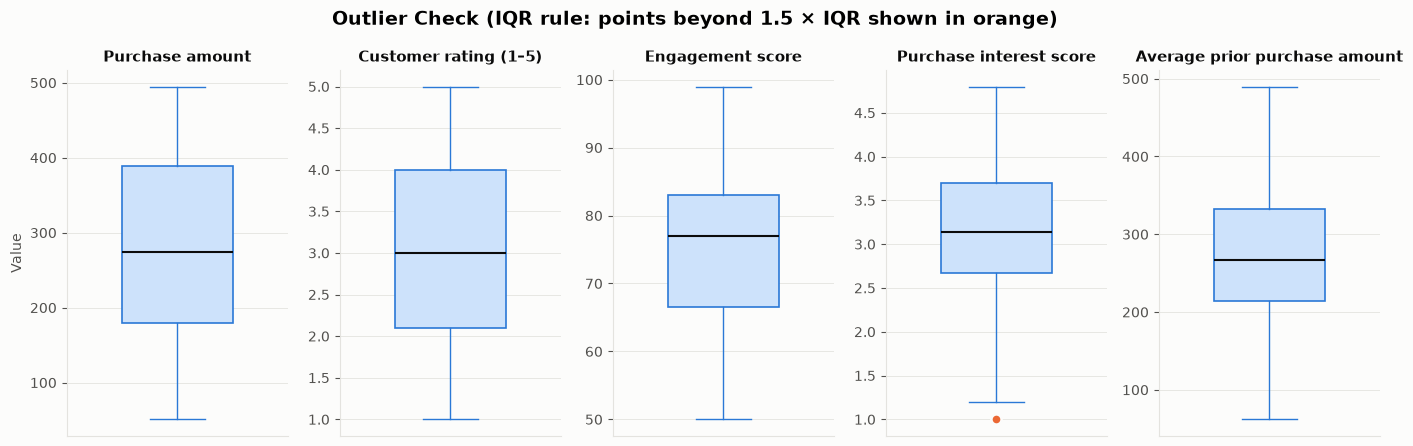

In [11]:
fig, axes = plt.subplots(1, len(OUTLIER_COLS), figsize=(14, 4.5))
labels = dict(DIST)
for ax, col in zip(axes, OUTLIER_COLS):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE, linewidth=1.2),
               medianprops=dict(color=INK, linewidth=1.5),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=7, markerfacecolor="#eb6834",
                               markeredgecolor=SURFACE, markeredgewidth=1.5))
    ax.set_title(labels[col], fontsize=10.5)
    ax.set_xticks([])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Value")
fig.suptitle("Outlier Check (IQR rule: points beyond 1.5 × IQR shown in orange)", fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "03_outliers_boxplots")
plt.show()

**Interpretation**

- Using the 1.5 × IQR rule, **purchase amount, customer rating, engagement score and average prior purchase amount have no outliers**. Their values stay within plausible, bounded ranges.
- The only flagged points are **4 rows with a very low purchase interest score** (around 1.0, against a typical 2.7–3.7). They are valid values on the 1–5 scale, not entry errors, so they are **kept**. Removing them would throw away real low-interest customers.
- No outlier treatment (capping or removal) is needed for this dataset.

## 7. Correlation between numeric variables

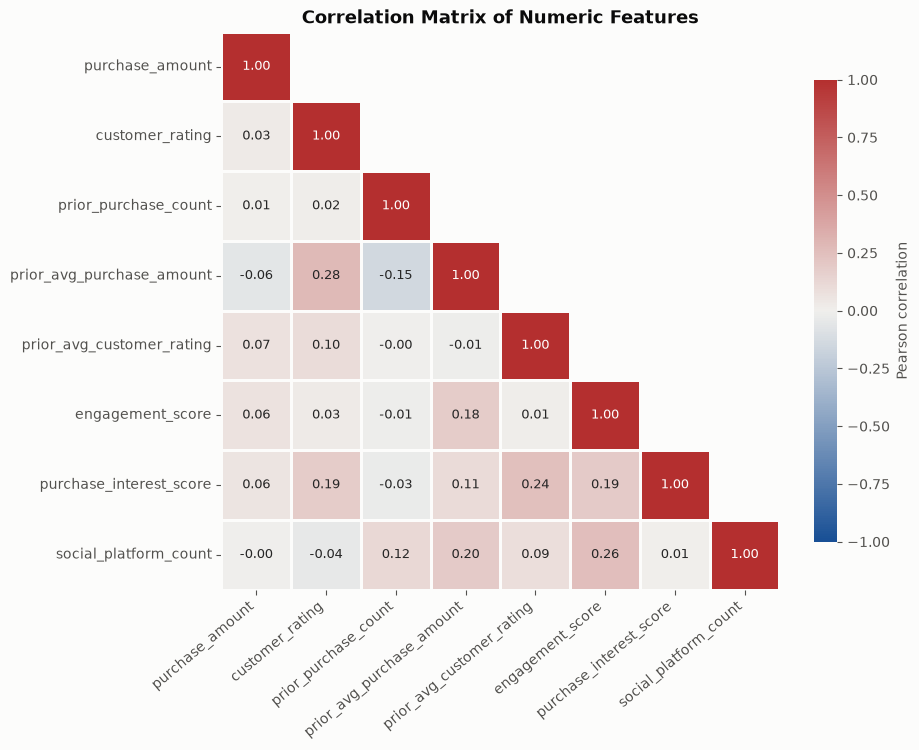

In [12]:
CORR_COLS = ["purchase_amount", "customer_rating", "prior_purchase_count", "prior_avg_purchase_amount",
             "prior_avg_customer_rating", "engagement_score", "purchase_interest_score", "social_platform_count"]
corr = df[CORR_COLS].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 9}, linewidths=2, linecolor=SURFACE, square=True,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix of Numeric Features")
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "04_correlation_heatmap")
plt.show()

In [13]:
pairs = (corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
pairs["|r|"] = pairs["r"].abs()
pairs.sort_values("|r|", ascending=False).head(5).round(2)

,feature_a,feature_b,r,|r|
11,customer_rating,prior_avg_purchase_amount,0.28,0.28
47,engagement_score,social_platform_count,0.26,0.26
38,prior_avg_customer_rating,purchase_interest_score,0.24,0.24
31,prior_avg_purchase_amount,social_platform_count,0.20,0.20
46,engagement_score,purchase_interest_score,0.19,0.19


**Interpretation**

- **All correlations are weak** (|r| < 0.3), so there is **no multicollinearity** problem. Every numeric feature brings separate information, and none needs to be dropped for redundancy (apart from the duplicate columns identified in Section 4).
- The strongest relationships are modest and intuitive:
  - **average prior purchase amount ↔ current rating (0.28)**: customers who spent more in the past tend to rate the current purchase slightly higher;
  - **engagement ↔ number of platforms (0.26)**: customers present on more platforms engage slightly more;
  - **purchase interest ↔ prior rating (0.24)**.
- **Purchase amount is essentially uncorrelated with every other feature** (|r| ≤ 0.07). Social engagement does not translate into spending in this dataset.

## 8. Features vs. the target `product_category`

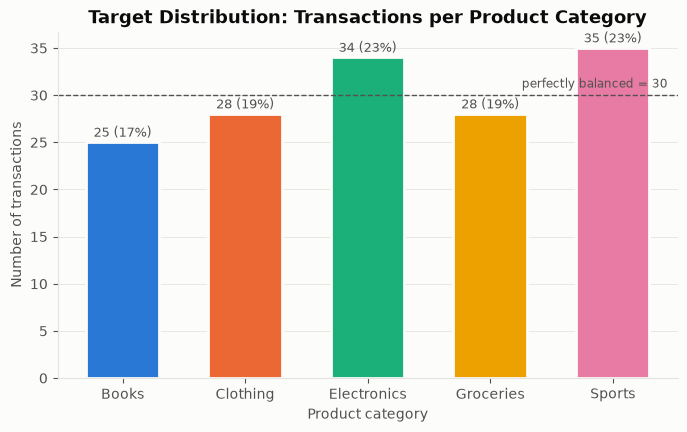

In [14]:
order = sorted(df["product_category"].unique())
counts = df["product_category"].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(order, counts.values, color=[CATEGORY_COLORS[c] for c in order], width=0.6, edgecolor=SURFACE, linewidth=2)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f"{v} ({v / len(df):.0%})", ha="center", color=INK_2, fontsize=9)
ax.axhline(len(df) / len(order), color=INK_2, linestyle="--", linewidth=1)
ax.text(len(order) - 0.55, len(df) / len(order) + 0.8, "perfectly balanced = 30", ha="right", fontsize=8.5, color=INK_2)
ax.set_title("Target Distribution: Transactions per Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Number of transactions")
ax.grid(axis="x", visible=False)
save(fig, "05_target_distribution")
plt.show()

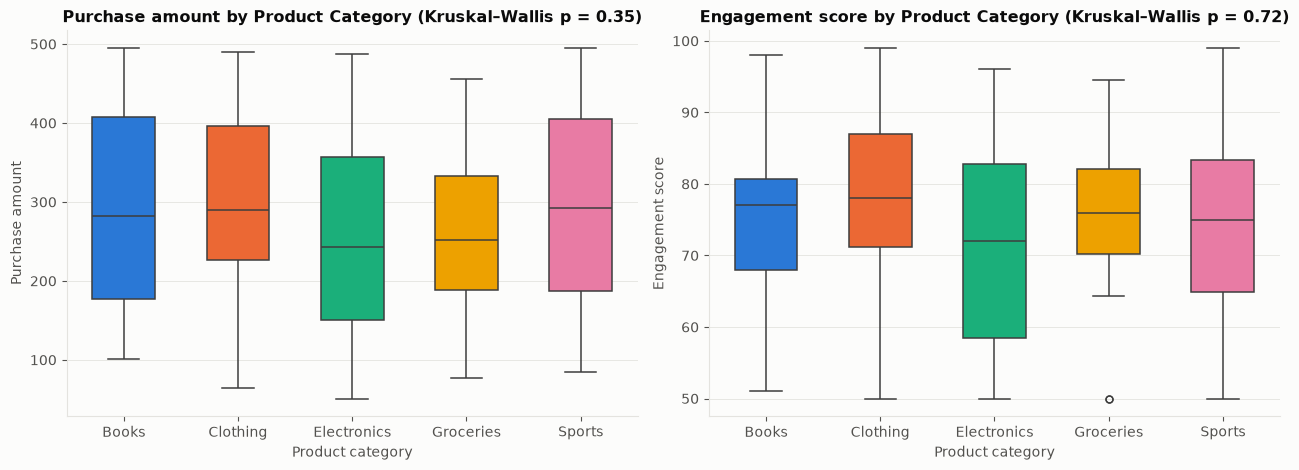

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (col, label) in zip(axes, [("purchase_amount", "Purchase amount"), ("engagement_score", "Engagement score")]):
    sns.boxplot(data=df, x="product_category", y=col, order=order, hue="product_category", hue_order=order,
                palette=CATEGORY_COLORS, saturation=1, legend=False, width=0.55, linewidth=1.1, fliersize=5, ax=ax)
    groups = [g[col].dropna() for _, g in df.groupby("product_category")]
    h, p = stats.kruskal(*groups)
    ax.set_title(f"{label} by Product Category (Kruskal–Wallis p = {p:.2f})", fontsize=11.5)
    ax.set_xlabel("Product category")
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "06_numeric_by_category")
plt.show()

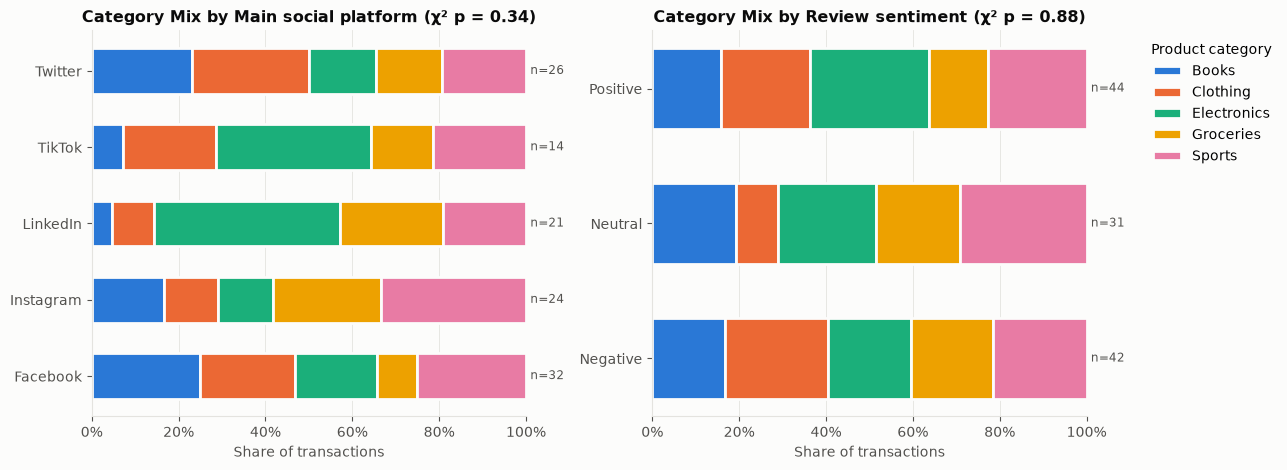

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
tests = []
for ax, (col, label) in zip(axes, [("main_platform", "Main social platform"), ("review_sentiment", "Review sentiment")]):
    ct = pd.crosstab(df[col], df["product_category"]).reindex(columns=order)
    share = ct.div(ct.sum(axis=1), axis=0)
    left = np.zeros(len(share))
    for cat in order:
        ax.barh(share.index, share[cat], left=left, color=CATEGORY_COLORS[cat], label=cat,
                height=0.6, edgecolor=SURFACE, linewidth=2)
        left += share[cat].values
    for y, n in enumerate(ct.sum(axis=1)):
        ax.text(1.01, y, f"n={n}", va="center", fontsize=8.5, color=INK_2)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    tests.append({"feature": col, "chi2": round(chi2, 2), "dof": dof, "p_value": round(p, 3)})
    ax.set_title(f"Category Mix by {label} (χ² p = {p:.2f})", fontsize=11.5)
    ax.set_xlabel("Share of transactions")
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
axes[1].legend(title="Product category", bbox_to_anchor=(1.12, 1), loc="upper left")
fig.tight_layout()
save(fig, "07_categorical_by_category")
plt.show()

In [17]:
# Association of every feature with the target in one table
rows = []
for col in NUMERIC:
    groups = [g[col].dropna() for _, g in df.groupby("product_category")]
    h, p = stats.kruskal(*groups)
    rows.append({"feature": col, "test": "Kruskal–Wallis", "statistic": round(h, 2), "p_value": round(p, 3)})
for col in ["main_platform", "review_sentiment", "engagement_level"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df["product_category"]))
    rows.append({"feature": col, "test": "Chi-square", "statistic": round(chi2, 2), "p_value": round(p, 3)})
association = pd.DataFrame(rows).sort_values("p_value")
association["significant_at_5%"] = association["p_value"] < 0.05
association

,feature,test,statistic,p_value,significant_at_5%
6,purchase_interest_score,Kruskal–Wallis,8.79,0.067,False
4,prior_avg_customer_rating,Kruskal–Wallis,8.70,0.069,False
2,prior_purchase_count,Kruskal–Wallis,5.70,0.223,False
10,engagement_level,Chi-square,4.87,0.301,False
8,main_platform,Chi-square,17.65,0.345,False
0,purchase_amount,Kruskal–Wallis,4.45,0.349,False
3,prior_avg_purchase_amount,Kruskal–Wallis,3.46,0.484,False
7,social_platform_count,Kruskal–Wallis,3.23,0.520,False
1,customer_rating,Kruskal–Wallis,2.41,0.661,False
5,engagement_score,Kruskal–Wallis,2.06,0.725,False


**Interpretation**

- **The target is fairly balanced.** The five categories range from 25 (Books, 17%) to 35 (Sports, 23%), close to the 30 per class a perfectly balanced dataset would have. Accuracy is therefore a meaningful metric, and class weighting is only a minor correction.
- **Purchase amount and engagement look almost the same across categories.** Electronics and Groceries have slightly lower median amounts (≈ 245–250 vs ≈ 280–290), but the Kruskal–Wallis tests are far from significant.
- **Platform and sentiment barely change the category mix.** The main visible pattern is that LinkedIn users lean towards Electronics (9 of 21 transactions). Each group is small, though, and the χ² test is not significant.
- **No feature has a statistically significant association with the product category** (every p-value is above 0.05). The closest are purchase interest score (p ≈ 0.07) and average prior rating (p ≈ 0.07). These are weak hints that may be worth keeping in the model, not reliable effects.

## 9. Purchases over time

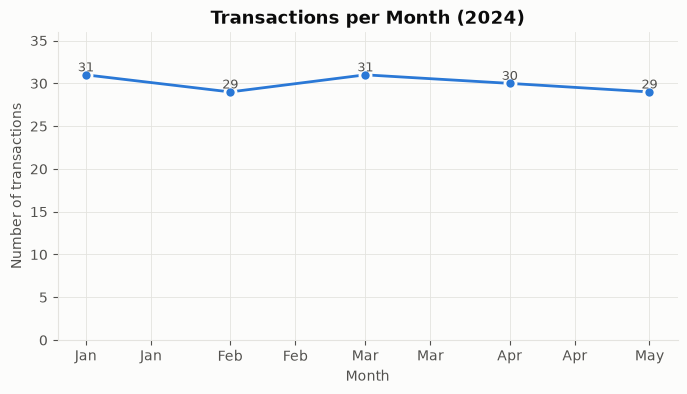

Transactions per calendar day: [1]


In [18]:
monthly = df.set_index("purchase_date").resample("MS").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
for x, v in zip(monthly.index, monthly.values):
    ax.text(x, v + 0.4, str(v), ha="center", fontsize=9, color=INK_2)
ax.set_ylim(0, monthly.max() + 5)
ax.set_title("Transactions per Month (2024)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of transactions")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
save(fig, "08_transactions_per_month")
plt.show()
print("Transactions per calendar day:", df["purchase_date"].dt.date.value_counts().unique())

**Interpretation**

The data covers **January to May 2024** with **exactly one transaction per day** (29–31 per month). There is no seasonality or growth trend to exploit, and date-based features such as month or weekday would carry no signal for the product category. The perfectly regular daily pattern also suggests the dataset is **synthetic**.

## 10. Key Findings and Implications for Modelling

| # | Finding | Implication |
|---|---|---|
| 1 | 150 transactions from 75 customers, 1–6 purchases each | A small dataset: use a customer-grouped train/test split (done in the product model) and expect high variance in the scores |
| 2 | Missing values are structural: 50% first purchases with no history, 22% customers without a social profile | Impute, and add a `has_history` / `has_social_profile` flag instead of dropping rows |
| 3 | No duplicates; merge did not multiply transactions | The left join on the aggregated social profile is valid |
| 4 | `platform_nunique` = `social_platform_count`, `customer_id` = `customer_id_legacy` | Drop one of each pair |
| 5 | Numeric features are near-uniform with no real outliers | No log transforms or outlier removal needed; standard scaling is enough |
| 6 | All correlations are weak (\|r\| < 0.3) | No multicollinearity; every feature can stay in the model |
| 7 | Target is close to balanced (17–23% per class) | Accuracy and macro-F1 are both meaningful; chance level is ≈ 20% |
| 8 | **No feature is significantly associated with `product_category`** | The features carry very little signal about which product is bought. This explains why the Random Forest scores around chance level (≈ 0.20 accuracy); the limit comes from the data, not the algorithm |
| 9 | One transaction per day, no time trend | Date features add no value; the data appears synthetic |

**Recommendations for the product model:** keep the model simple and well regularised (for example Logistic Regression, or a shallow Random Forest), report macro-F1 and log-loss against the 20% chance baseline, and present the recommendation as a **ranked list with probabilities** rather than a single "certain" product.